In [19]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

In [20]:
df = pd.read_csv("../KG_Obesity_Artifact/ObesityDataSet_raw_and_data_sinthetic.csv")
df_clean = df.copy()
df_clean.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [21]:
df_clean.drop_duplicates(inplace = True)
df_clean.shape

(2087, 17)

In [22]:
df_clean ['Gender'] = df_clean['Gender'].map({"Male" : 0,"Female" : 1})
df_clean.rename (columns={'Gender' : 'Female'}, inplace = True)
df_clean.head()

,Female,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,1,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,1,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,0,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,0,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,0,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [23]:
df_clean ['family_history_with_overweight'] = df_clean['family_history_with_overweight'].map({"no" : 0, "yes" : 1})
df_clean.rename (columns={'family_history_with_overweight' : 'Family_History'}, inplace = True)
df_clean.head()

,Female,Age,Height,Weight,Family_History,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,1,21.0,1.62,64.0,1,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,1,21.0,1.52,56.0,1,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,0,23.0,1.80,77.0,1,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,0,27.0,1.80,87.0,0,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,0,22.0,1.78,89.8,0,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [24]:
df_clean ['FAVC'] = df_clean['FAVC'].map({"no" : 0, "yes" : 1})
df_clean ['SMOKE'] = df_clean['SMOKE'].map({"no" : 0, "yes" : 1})
df_clean ['SCC'] = df_clean['SCC'].map({"no" : 0, "yes" : 1})
df_clean.head()

,Female,Age,Height,Weight,Family_History,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,1,21.0,1.62,64.0,1,0,2.0,3.0,Sometimes,0,2.0,0,0.0,1.0,no,Public_Transportation,Normal_Weight
1,1,21.0,1.52,56.0,1,0,3.0,3.0,Sometimes,1,3.0,1,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,0,23.0,1.80,77.0,1,0,2.0,3.0,Sometimes,0,2.0,0,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,0,27.0,1.80,87.0,0,0,3.0,3.0,Sometimes,0,2.0,0,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,0,22.0,1.78,89.8,0,0,2.0,1.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [25]:
df_clean["MTRANS"] = df_clean["MTRANS"].replace({
    "Public_Transportation": "Public",
    "Automobile": "Car",
    "Bike": "Cycle"
})

df_clean["MTRANS"].value_counts()

MTRANS
Public       1558
Car           456
Walking        55
Motorbike      11
Cycle           7
Name: count, dtype: int64

In [26]:
df_clean.rename (columns={'NObeyesdad' : 'Obesity_Level'}, inplace = True)

In [27]:
import os
import joblib
from sklearn.preprocessing import LabelEncoder

cols_to_encode = ["Obesity_Level", "MTRANS", "CALC", "CAEC"]

artifact_dir = "../KG_Obesity_Artifact"
os.makedirs(artifact_dir, exist_ok=True)

encoders = {}
for col in cols_to_encode:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col])          # learn mapping and encode
    encoders[col] = le
    joblib.dump(le, f"{artifact_dir}/KG_Encoder_{col}.joblib")   # one file per encoder

    # print the mapping so you can verify it
    print(col, dict(zip(le.classes_, le.transform(le.classes_))))

Obesity_Level {'Insufficient_Weight': np.int64(0), 'Normal_Weight': np.int64(1), 'Obesity_Type_I': np.int64(2), 'Obesity_Type_II': np.int64(3), 'Obesity_Type_III': np.int64(4), 'Overweight_Level_I': np.int64(5), 'Overweight_Level_II': np.int64(6)}
MTRANS {'Car': np.int64(0), 'Cycle': np.int64(1), 'Motorbike': np.int64(2), 'Public': np.int64(3), 'Walking': np.int64(4)}
CALC {'Always': np.int64(0), 'Frequently': np.int64(1), 'Sometimes': np.int64(2), 'no': np.int64(3)}
CAEC {'Always': np.int64(0), 'Frequently': np.int64(1), 'Sometimes': np.int64(2), 'no': np.int64(3)}


In [28]:
df_clean.head()

,Female,Age,Height,Weight,Family_History,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity_Level
0,1,21.0,1.62,64.0,1,0,2.0,3.0,2,0,2.0,0,0.0,1.0,3,3,1
1,1,21.0,1.52,56.0,1,0,3.0,3.0,2,1,3.0,1,3.0,0.0,2,3,1
2,0,23.0,1.80,77.0,1,0,2.0,3.0,2,0,2.0,0,2.0,1.0,1,3,1
3,0,27.0,1.80,87.0,0,0,3.0,3.0,2,0,2.0,0,2.0,0.0,1,4,5
4,0,22.0,1.78,89.8,0,0,2.0,1.0,2,0,2.0,0,0.0,0.0,2,3,6


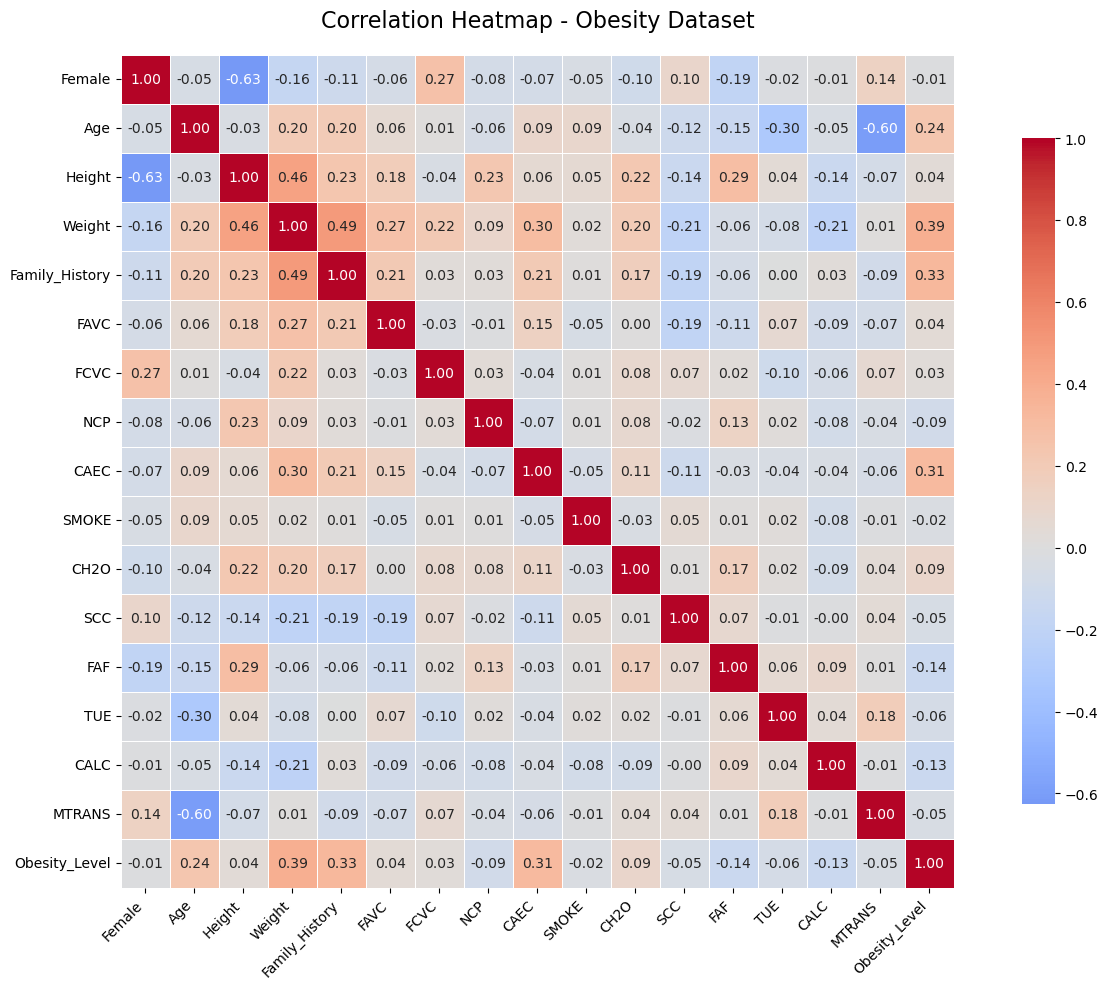

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming your dataframe is called df
# Make sure all columns are numeric (you already encoded them)

plt.figure(figsize=(14, 10))

# Create correlation matrix
corr = df_clean.corr()

# Heatmap with labels
sns.heatmap(
    corr,
    annot=True,           # Show correlation values
    fmt=".2f",            # 2 decimal places
    cmap="coolwarm",      # Nice color scale (blue = negative, red = positive)
    center=0,             # Center the colormap at 0
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Heatmap - Obesity Dataset", fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [38]:
import os

df_clean.to_csv("../KG_Obesity_Artifact/KG_Obesity_Cleaned.csv", index=False)

print("Saved successfully!")

Saved successfully!


In [39]:
from scipy.stats import pearsonr, spearmanr

# Features and target
features = df_clean.drop(columns=["Obesity_Level"]).columns
results = []

for col in features:
    # Pearson
    pearson_corr, pearson_p = pearsonr(df_clean[col], df_clean["Obesity_Level"])
    
    # Spearman (recommended for ordinal target)
    spearman_corr, spearman_p = spearmanr(df_clean[col], df_clean["Obesity_Level"])
    
    results.append({
        "Feature": col,
        "Pearson_Corr": round(pearson_corr, 4),
        "Pearson_p_value": round(pearson_p, 4),
        "Spearman_Corr": round(spearman_corr, 4),
        "Spearman_p_value": round(spearman_p, 4),
        "Significant (p<0.05)": "Yes" if spearman_p < 0.05 else "No"
    })

# Create DataFrame and sort by absolute Spearman correlation
corr_df = pd.DataFrame(results)
corr_df["Abs_Spearman"] = corr_df["Spearman_Corr"].abs()
corr_df = corr_df.sort_values("Abs_Spearman", ascending=False).drop(columns="Abs_Spearman")

# Display the result
corr_df

,Feature,Pearson_Corr,Pearson_p_value,Spearman_Corr,Spearman_p_value,Significant (p<0.05)
3,Weight,0.3888,0.0000,0.4048,0.0000,Yes
8,CAEC,0.3145,0.0000,0.3457,0.0000,Yes
4,Family_History,0.3304,0.0000,0.3315,0.0000,Yes
1,Age,0.2383,0.0000,0.2870,0.0000,Yes
7,NCP,-0.0882,0.0001,-0.1416,0.0000,Yes
14,CALC,-0.1328,0.0000,-0.1392,0.0000,Yes
12,FAF,-0.1352,0.0000,-0.1336,0.0000,Yes
10,CH2O,0.0926,0.0000,0.0904,0.0000,Yes
15,MTRANS,-0.0478,0.0290,-0.0526,0.0162,Yes
13,TUE,-0.0649,0.0030,-0.0525,0.0165,Yes
